# CS3807 – Deep Learning Laboratory
# Experiment 7: Autoencoders, Convolutional AE, Denoising AE, Variational AE

This notebook covers, in order: setup -> data -> Fully Connected AE -> Convolutional AE ->
Denoising AE (Gaussian + salt-and-pepper noise) -> Variational AE -> latent-dimension study ->
consolidated results -> discussion questions.

All figures are saved to `plots/` (bold titles, bold axis labels, bold legends, 150 dpi so they
import cleanly into Overleaf).

## 1. Setup

In [1]:
import os, time, gc, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from skimage.metrics import structural_similarity as ssim

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

os.makedirs("plots", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ---- Plot styling helper: bold title / bold axis labels / bold legend, saved to plots/ ----
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "font.size": 11,
})

def style_axes(ax, title=None, xlabel=None, ylabel=None, legend=False):
    if title:
        ax.set_title(title, fontweight="bold")
    if xlabel:
        ax.set_xlabel(xlabel, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel, fontweight="bold")
    if legend:
        leg = ax.legend(prop={"weight": "bold"})
    return ax

def save_plot(fig, name):
    path = os.path.join("plots", name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)

def reset_keras():
    keras.backend.clear_session()
    gc.collect()

## 2. Dataset and Preprocessing (MNIST, 10,000 train / 2,000 test subset)

In [3]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.mnist.load_data()

N_TRAIN, N_TEST = 10000, 2000

rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(x_train_full), N_TRAIN, replace=False)
test_idx  = rng.choice(len(x_test_full), N_TEST, replace=False)

x_train = x_train_full[train_idx].astype("float32") / 255.0
y_train = y_train_full[train_idx]
x_test  = x_test_full[test_idx].astype("float32") / 255.0
y_test  = y_test_full[test_idx]

x_train = x_train[..., np.newaxis]   # (N, 28, 28, 1)
x_test  = x_test[..., np.newaxis]

x_train_flat = x_train.reshape(len(x_train), -1)   # (N, 784)
x_test_flat  = x_test.reshape(len(x_test), -1)

print("x_train:", x_train.shape, " x_train_flat:", x_train_flat.shape)
print("x_test :", x_test.shape,  " x_test_flat :", x_test_flat.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (10000, 28, 28, 1)  x_train_flat: (10000, 784)
x_test : (2000, 28, 28, 1)  x_test_flat : (2000, 784)


## 3. Metric Utilities (MSE, MAE, SSIM) and Reusable Plot Functions

In [4]:
def compute_metrics(x_true, x_pred):
    # x_true, x_pred: (N, 28, 28, 1) or (N, 784) arrays in [0,1]
    x_true_img = x_true.reshape(-1, 28, 28)
    x_pred_img = x_pred.reshape(-1, 28, 28)
    mse = np.mean((x_true_img - x_pred_img) ** 2)
    mae = np.mean(np.abs(x_true_img - x_pred_img))
    ssim_vals = [ssim(x_true_img[i], x_pred_img[i], data_range=1.0) for i in range(len(x_true_img))]
    return mse, mae, float(np.mean(ssim_vals))

def per_image_error(x_true, x_pred):
    x_true_img = x_true.reshape(-1, 28 * 28)
    x_pred_img = x_pred.reshape(-1, 28 * 28)
    return np.mean((x_true_img - x_pred_img) ** 2, axis=1)

def count_params(model):
    return model.count_params()

def plot_original_vs_recon(originals, recons, n=10, title="Original vs Reconstructed", fname="plot1_original_vs_recon.png", show_error=True):
    rows = 3 if show_error else 2
    fig, axes = plt.subplots(rows, n, figsize=(1.4 * n, 1.6 * rows))
    if show_error:
        errors = per_image_error(originals[:n], recons[:n])
    for i in range(n):
        axes[0, i].imshow(originals[i].reshape(28, 28), cmap="gray")
        axes[0, i].axis("off")
        axes[1, i].imshow(recons[i].reshape(28, 28), cmap="gray")
        axes[1, i].axis("off")
        if show_error:
            err_map = np.abs(originals[i].reshape(28, 28) - recons[i].reshape(28, 28))
            axes[2, i].imshow(err_map, cmap="hot", vmin=0, vmax=1)
            axes[2, i].set_title(f"MSE={errors[i]:.4f}", fontsize=8, fontweight="bold")
            axes[2, i].axis("off")
    axes[0, 0].set_ylabel("Original", fontweight="bold")
    axes[1, 0].set_ylabel("Reconstructed", fontweight="bold")
    if show_error:
        axes[2, 0].set_ylabel("Recon. Error", fontweight="bold")
    fig.suptitle(title, fontweight="bold")
    save_plot(fig, fname)
    plt.show()

def plot_loss_curve(history, title, fname, keys=("loss", "val_loss")):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(history.history[keys[0]], label="Training Loss", linewidth=2)
    ax.plot(history.history[keys[1]], label="Validation Loss", linewidth=2)
    style_axes(ax, title=title, xlabel="Epoch", ylabel="Reconstruction Loss", legend=True)
    save_plot(fig, fname)
    plt.show()

## 4. Fully Connected Autoencoder
Architecture: `784 -> 128 -> 32 -> 16 (latent) -> 32 -> 128 -> 784`, ReLU hidden layers, sigmoid output,
Adam (lr=1e-3), batch size 128, 20 epochs, binary cross-entropy loss.

In [5]:
def build_fc_autoencoder(latent_dim=16):
    inp = layers.Input(shape=(784,), name="input")
    x = layers.Dense(128, activation="relu")(inp)
    x = layers.Dense(32, activation="relu")(x)
    z = layers.Dense(latent_dim, activation="relu", name="latent")(x)
    x = layers.Dense(32, activation="relu")(z)
    x = layers.Dense(128, activation="relu")(x)
    out = layers.Dense(784, activation="sigmoid")(x)
    autoencoder = keras.Model(inp, out, name=f"FC_AE_z{latent_dim}")
    encoder = keras.Model(inp, z, name=f"FC_Encoder_z{latent_dim}")
    autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return autoencoder, encoder

reset_keras()
fc_ae, fc_encoder = build_fc_autoencoder(latent_dim=16)
fc_ae.summary()

Model: "FC_AE_z16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
start = time.time()
fc_history = fc_ae.fit(
    x_train_flat, x_train_flat,
    validation_data=(x_test_flat, x_test_flat),
    epochs=20, batch_size=128, verbose=2
)
fc_time = time.time() - start
print(f"FC-AE training time: {fc_time:.1f}s")

Epoch 1/20
79/79 - 7s - 90ms/step - loss: 0.3468 - val_loss: 0.2493
Epoch 2/20
79/79 - 0s - 4ms/step - loss: 0.2301 - val_loss: 0.2079
Epoch 3/20
79/79 - 0s - 4ms/step - loss: 0.1961 - val_loss: 0.1869
Epoch 4/20
79/79 - 0s - 4ms/step - loss: 0.1796 - val_loss: 0.1702
Epoch 5/20
79/79 - 0s - 4ms/step - loss: 0.1654 - val_loss: 0.1580
Epoch 6/20
79/79 - 0s - 4ms/step - loss: 0.1547 - val_loss: 0.1502
Epoch 7/20
79/79 - 0s - 4ms/step - loss: 0.1487 - val_loss: 0.1461
Epoch 8/20
79/79 - 0s - 4ms/step - loss: 0.1451 - val_loss: 0.1430
Epoch 9/20
79/79 - 0s - 4ms/step - loss: 0.1423 - val_loss: 0.1407
Epoch 10/20
79/79 - 0s - 4ms/step - loss: 0.1399 - val_loss: 0.1387
Epoch 11/20
79/79 - 0s - 4ms/step - loss: 0.1377 - val_loss: 0.1364
Epoch 12/20
79/79 - 0s - 4ms/step - loss: 0.1356 - val_loss: 0.1339
Epoch 13/20
79/79 - 0s - 4ms/step - loss: 0.1333 - val_loss: 0.1326
Epoch 14/20
79/79 - 0s - 4ms/step - loss: 0.1313 - val_loss: 0.1306
Epoch 15/20
79/79 - 0s - 4ms/step - loss: 0.1297 - val_l

In [7]:
fc_recon = fc_ae.predict(x_test_flat, verbose=0)
fc_mse, fc_mae, fc_ssim = compute_metrics(x_test_flat, fc_recon)
print(f"FC-AE  ->  MSE: {fc_mse:.5f}  MAE: {fc_mae:.5f}  SSIM: {fc_ssim:.4f}  Params: {count_params(fc_ae)}")

FC-AE  ->  MSE: 0.01996  MAE: 0.05433  SSIM: 0.7733  Params: 211040


### Plot 1 — Original vs Reconstructed (Fully Connected AE)

Saved: plots/plot1_fc_original_vs_recon.png


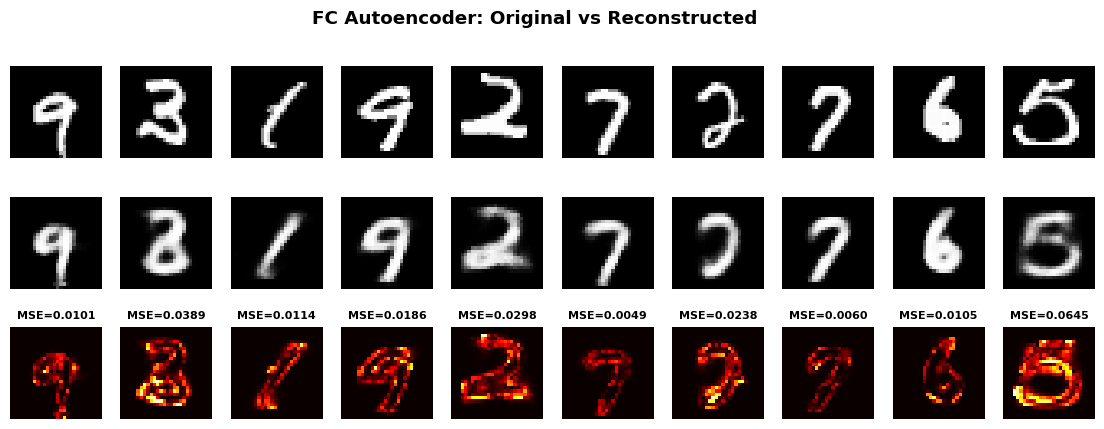

In [8]:
plot_original_vs_recon(x_test_flat, fc_recon, n=10,
                        title="FC Autoencoder: Original vs Reconstructed",
                        fname="plot1_fc_original_vs_recon.png")

### Plot 2 — Training vs Validation Reconstruction Loss (FC-AE)

Saved: plots/plot2_fc_loss_curve.png


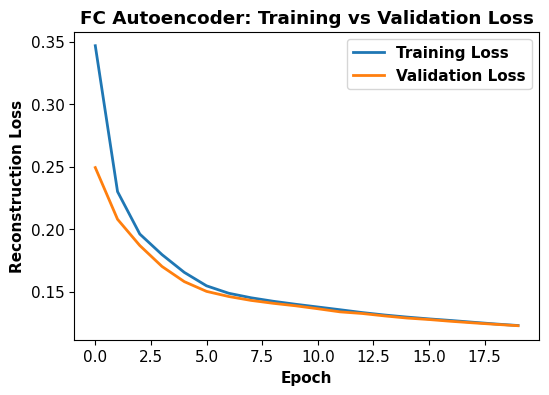

In [9]:
plot_loss_curve(fc_history, "FC Autoencoder: Training vs Validation Loss", "plot2_fc_loss_curve.png")

**Inference:** the model converges if both curves flatten; overfitting is indicated if validation
loss rises while training loss keeps falling.

## 5. Convolutional Autoencoder (CAE)

In [10]:
def build_conv_autoencoder():
    inp = layers.Input(shape=(28, 28, 1), name="input")
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)
    z = layers.Conv2D(64, 3, activation="relu", padding="same", name="latent_feature_map")(x)

    x = layers.UpSampling2D(2)(z)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

    autoencoder = keras.Model(inp, out, name="Conv_AE")
    encoder = keras.Model(inp, z, name="Conv_Encoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return autoencoder, encoder

reset_keras()
cae, cae_encoder = build_conv_autoencoder()
cae.summary()

Model: "Conv_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_feature_map (Conv2D)     │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
start = time.time()
cae_history = cae.fit(
    x_train, x_train,
    validation_data=(x_test, x_test),
    epochs=20, batch_size=128, verbose=2
)
cae_time = time.time() - start
print(f"Conv-AE training time: {cae_time:.1f}s")

Epoch 1/20
79/79 - 9s - 114ms/step - loss: 0.2480 - val_loss: 0.1040
Epoch 2/20
79/79 - 4s - 49ms/step - loss: 0.0939 - val_loss: 0.0883
Epoch 3/20
79/79 - 1s - 9ms/step - loss: 0.0841 - val_loss: 0.0803
Epoch 4/20
79/79 - 1s - 8ms/step - loss: 0.0802 - val_loss: 0.0778
Epoch 5/20
79/79 - 1s - 8ms/step - loss: 0.0777 - val_loss: 0.0756
Epoch 6/20
79/79 - 1s - 8ms/step - loss: 0.0757 - val_loss: 0.0741
Epoch 7/20
79/79 - 1s - 8ms/step - loss: 0.0743 - val_loss: 0.0729
Epoch 8/20
79/79 - 1s - 8ms/step - loss: 0.0734 - val_loss: 0.0723
Epoch 9/20
79/79 - 1s - 8ms/step - loss: 0.0725 - val_loss: 0.0715
Epoch 10/20
79/79 - 1s - 8ms/step - loss: 0.0720 - val_loss: 0.0709
Epoch 11/20
79/79 - 1s - 8ms/step - loss: 0.0714 - val_loss: 0.0704
Epoch 12/20
79/79 - 1s - 8ms/step - loss: 0.0710 - val_loss: 0.0700
Epoch 13/20
79/79 - 1s - 8ms/step - loss: 0.0705 - val_loss: 0.0697
Epoch 14/20
79/79 - 1s - 8ms/step - loss: 0.0702 - val_loss: 0.0694
Epoch 15/20
79/79 - 1s - 8ms/step - loss: 0.0698 - val

In [12]:
cae_recon = cae.predict(x_test, verbose=0)
cae_mse, cae_mae, cae_ssim = compute_metrics(x_test, cae_recon)
print(f"Conv-AE  ->  MSE: {cae_mse:.5f}  MAE: {cae_mae:.5f}  SSIM: {cae_ssim:.4f}  Params: {count_params(cae)}")

Conv-AE  ->  MSE: 0.00248  MAE: 0.01506  SSIM: 0.9748  Params: 74497


Saved: plots/plot1b_cae_original_vs_recon.png


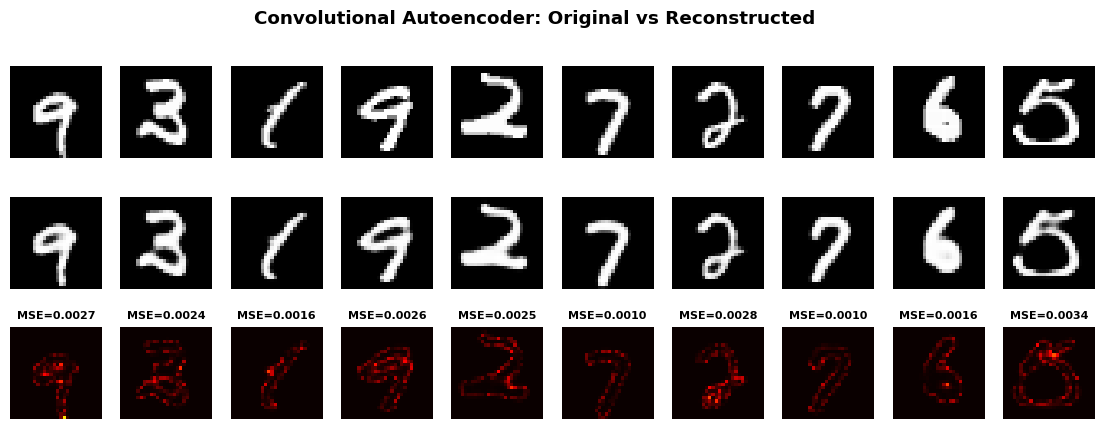

Saved: plots/plot2b_cae_loss_curve.png


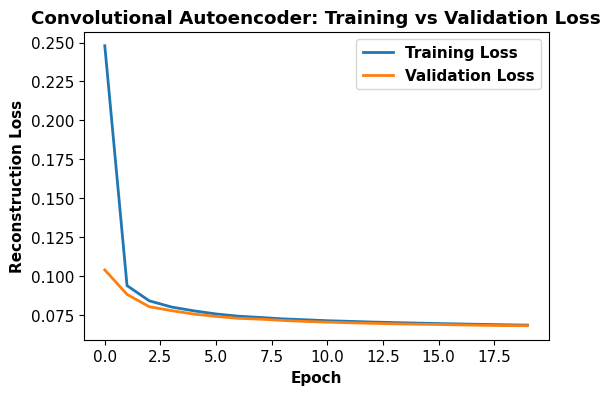

In [13]:
plot_original_vs_recon(x_test, cae_recon, n=10,
                        title="Convolutional Autoencoder: Original vs Reconstructed",
                        fname="plot1b_cae_original_vs_recon.png")
plot_loss_curve(cae_history, "Convolutional Autoencoder: Training vs Validation Loss", "plot2b_cae_loss_curve.png")

## 6. Comparing Fully Connected and Convolutional Autoencoders

In [14]:
print(f"{'Model':<20}{'MSE':<12}{'MAE':<12}{'SSIM':<10}{'Params':<10}")
print(f"{'Fully Connected AE':<20}{fc_mse:<12.5f}{fc_mae:<12.5f}{fc_ssim:<10.4f}{count_params(fc_ae):<10}")
print(f"{'Convolutional AE':<20}{cae_mse:<12.5f}{cae_mae:<12.5f}{cae_ssim:<10.4f}{count_params(cae):<10}")

Model               MSE         MAE         SSIM      Params    
Fully Connected AE  0.01996     0.05433     0.7733    211040    
Convolutional AE    0.00248     0.01506     0.9748    74497     


### Plot 3 — Reconstruction Comparison: Original -> FC-AE -> CAE

Saved: plots/plot3_fc_vs_cae.png


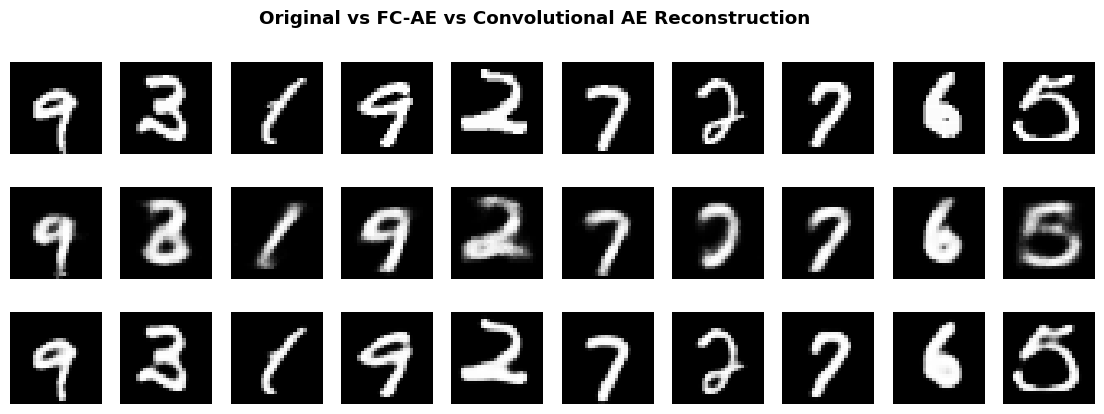

In [15]:
n = 10
fig, axes = plt.subplots(3, n, figsize=(1.4 * n, 4.6))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(fc_recon[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(cae_recon[i].reshape(28, 28), cmap="gray"); axes[2, i].axis("off")
axes[0, 0].set_ylabel("Original", fontweight="bold")
axes[1, 0].set_ylabel("FC-AE", fontweight="bold")
axes[2, 0].set_ylabel("CAE", fontweight="bold")
fig.suptitle("Original vs FC-AE vs Convolutional AE Reconstruction", fontweight="bold")
save_plot(fig, "plot3_fc_vs_cae.png")
plt.show()

## 7. Denoising Convolutional Autoencoder
Two corruption types are used: **Gaussian noise** (sigma in {0.1, 0.2, 0.3}) and
**salt-and-pepper noise** (p in {0.05, 0.10, 0.20}). The target is always the *clean* image.

In [16]:
def add_gaussian_noise(x, sigma):
    noisy = x + np.random.normal(0, sigma, x.shape)
    return np.clip(noisy, 0.0, 1.0).astype("float32")

def add_salt_and_pepper_noise(x, p):
    noisy = x.copy()
    mask = np.random.rand(*x.shape)
    noisy[mask < p / 2] = 0.0
    noisy[(mask >= p / 2) & (mask < p)] = 1.0
    return noisy.astype("float32")

def build_denoising_cae():
    # same architecture as the Convolutional Autoencoder
    return build_conv_autoencoder()

### Train one denoising model per Gaussian noise level (sigma = 0.1, 0.2, 0.3)

In [17]:
gaussian_levels = [0.1, 0.2, 0.3]
denoise_models = {}
denoise_histories = {}
denoise_metrics = {}
denoise_times = {}

for sigma in gaussian_levels:
    print(f"\n=== Training denoising CAE at Gaussian sigma={sigma} ===")
    reset_keras()
    x_train_noisy = add_gaussian_noise(x_train, sigma)
    x_test_noisy = add_gaussian_noise(x_test, sigma)

    model, _ = build_denoising_cae()
    start = time.time()
    hist = model.fit(
        x_train_noisy, x_train,
        validation_data=(x_test_noisy, x_test),
        epochs=15, batch_size=128, verbose=2
    )
    denoise_times[sigma] = time.time() - start
    recon = model.predict(x_test_noisy, verbose=0)
    mse, mae, ssim_v = compute_metrics(x_test, recon)

    denoise_models[sigma] = model
    denoise_histories[sigma] = hist
    denoise_metrics[sigma] = (mse, mae, ssim_v)
    print(f"sigma={sigma}  MSE={mse:.5f}  MAE={mae:.5f}  SSIM={ssim_v:.4f}  Time={denoise_times[sigma]:.1f}s")

# use the sigma = 0.2 model as "the" Denoising CAE for later comparisons
denoise_cae = denoise_models[0.2]
denoise_mse, denoise_mae, denoise_ssim = denoise_metrics[0.2]
denoise_time = denoise_times[0.2]


=== Training denoising CAE at Gaussian sigma=0.1 ===
Epoch 1/15
79/79 - 6s - 71ms/step - loss: 0.2333 - val_loss: 0.1090
Epoch 2/15
79/79 - 1s - 9ms/step - loss: 0.0973 - val_loss: 0.0906
Epoch 3/15
79/79 - 1s - 9ms/step - loss: 0.0865 - val_loss: 0.0824
Epoch 4/15
79/79 - 1s - 9ms/step - loss: 0.0822 - val_loss: 0.0798
Epoch 5/15
79/79 - 1s - 10ms/step - loss: 0.0796 - val_loss: 0.0776
Epoch 6/15
79/79 - 1s - 14ms/step - loss: 0.0782 - val_loss: 0.0766
Epoch 7/15
79/79 - 1s - 8ms/step - loss: 0.0769 - val_loss: 0.0754
Epoch 8/15
79/79 - 1s - 8ms/step - loss: 0.0759 - val_loss: 0.0746
Epoch 9/15
79/79 - 1s - 8ms/step - loss: 0.0752 - val_loss: 0.0740
Epoch 10/15
79/79 - 1s - 8ms/step - loss: 0.0747 - val_loss: 0.0740
Epoch 11/15
79/79 - 1s - 8ms/step - loss: 0.0741 - val_loss: 0.0731
Epoch 12/15
79/79 - 1s - 8ms/step - loss: 0.0735 - val_loss: 0.0731
Epoch 13/15
79/79 - 1s - 8ms/step - loss: 0.0732 - val_loss: 0.0724
Epoch 14/15
79/79 - 1s - 9ms/step - loss: 0.0728 - val_loss: 0.0723


### Train one denoising model per Salt-and-Pepper noise level (p = 0.05, 0.10, 0.20)

In [18]:
sp_levels = [0.05, 0.10, 0.20]
sp_models = {}
sp_metrics = {}
sp_times = {}

for p in sp_levels:
    print(f"\n=== Training denoising CAE at salt-and-pepper p={p} ===")
    reset_keras()
    x_train_sp = add_salt_and_pepper_noise(x_train, p)
    x_test_sp = add_salt_and_pepper_noise(x_test, p)

    model, _ = build_denoising_cae()
    start = time.time()
    model.fit(
        x_train_sp, x_train,
        validation_data=(x_test_sp, x_test),
        epochs=15, batch_size=128, verbose=2
    )
    sp_times[p] = time.time() - start
    recon = model.predict(x_test_sp, verbose=0)
    mse, mae, ssim_v = compute_metrics(x_test, recon)

    sp_models[p] = model
    sp_metrics[p] = (mse, mae, ssim_v)
    print(f"p={p}  MSE={mse:.5f}  MAE={mae:.5f}  SSIM={ssim_v:.4f}  Time={sp_times[p]:.1f}s")

# use the p = 0.10 model as "the" salt-and-pepper denoising model for Plot 4b
sp_denoise_model = sp_models[0.10]


=== Training denoising CAE at salt-and-pepper p=0.05 ===
Epoch 1/15
79/79 - 7s - 84ms/step - loss: 0.2447 - val_loss: 0.1163
Epoch 2/15
79/79 - 1s - 9ms/step - loss: 0.1007 - val_loss: 0.0925
Epoch 3/15
79/79 - 1s - 8ms/step - loss: 0.0887 - val_loss: 0.0857
Epoch 4/15
79/79 - 1s - 8ms/step - loss: 0.0841 - val_loss: 0.0818
Epoch 5/15
79/79 - 1s - 8ms/step - loss: 0.0814 - val_loss: 0.0804
Epoch 6/15
79/79 - 1s - 8ms/step - loss: 0.0797 - val_loss: 0.0781
Epoch 7/15
79/79 - 1s - 8ms/step - loss: 0.0783 - val_loss: 0.0769
Epoch 8/15
79/79 - 1s - 8ms/step - loss: 0.0773 - val_loss: 0.0760
Epoch 9/15
79/79 - 1s - 8ms/step - loss: 0.0764 - val_loss: 0.0753
Epoch 10/15
79/79 - 1s - 8ms/step - loss: 0.0758 - val_loss: 0.0748
Epoch 11/15
79/79 - 1s - 8ms/step - loss: 0.0750 - val_loss: 0.0742
Epoch 12/15
79/79 - 1s - 8ms/step - loss: 0.0746 - val_loss: 0.0738
Epoch 13/15
79/79 - 1s - 8ms/step - loss: 0.0741 - val_loss: 0.0734
Epoch 14/15
79/79 - 1s - 8ms/step - loss: 0.0738 - val_loss: 0.073

### Plot 4 — Clean vs Noisy vs Denoised (Gaussian, sigma = 0.2) and Salt-and-Pepper demo

Saved: plots/plot4a_denoising_gaussian.png


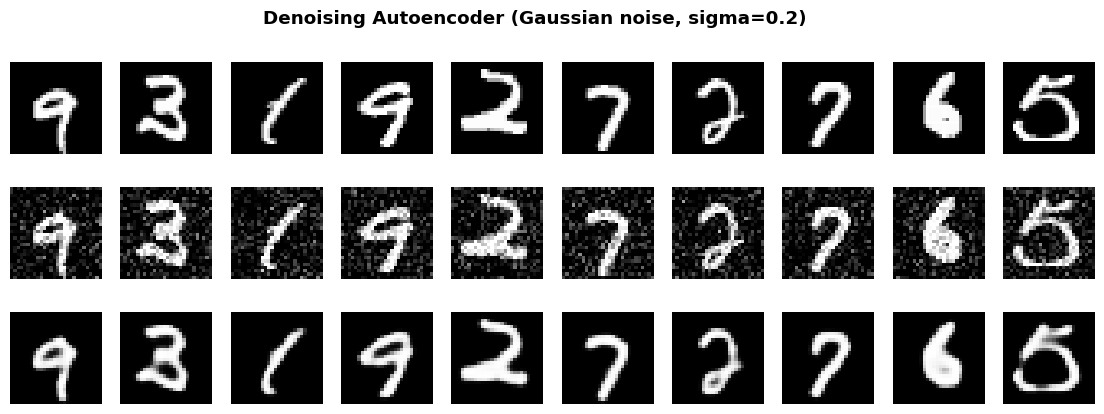

In [19]:
sigma_demo = 0.2
x_test_noisy_demo = add_gaussian_noise(x_test, sigma_demo)
denoised_demo = denoise_cae.predict(x_test_noisy_demo, verbose=0)

n = 10
fig, axes = plt.subplots(3, n, figsize=(1.4 * n, 4.6))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(x_test_noisy_demo[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(denoised_demo[i].reshape(28, 28), cmap="gray"); axes[2, i].axis("off")
axes[0, 0].set_ylabel("Clean", fontweight="bold")
axes[1, 0].set_ylabel("Noisy", fontweight="bold")
axes[2, 0].set_ylabel("Denoised", fontweight="bold")
fig.suptitle(f"Denoising Autoencoder (Gaussian noise, sigma={sigma_demo})", fontweight="bold")
save_plot(fig, "plot4a_denoising_gaussian.png")
plt.show()

Saved: plots/plot4b_denoising_salt_pepper.png


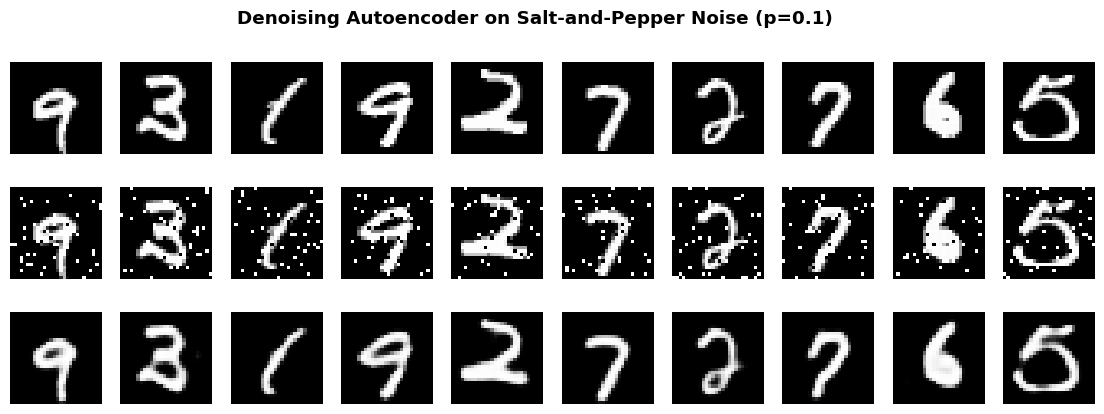

Salt-and-pepper (p=0.1), own trained model -> MSE=0.00512 MAE=0.02214 SSIM=0.9439


In [20]:
# Salt-and-pepper demonstration using its own properly-trained denoising model (p = 0.10)
p_demo = 0.10
x_test_sp_demo = add_salt_and_pepper_noise(x_test, p_demo)
denoised_sp_demo = sp_denoise_model.predict(x_test_sp_demo, verbose=0)

fig, axes = plt.subplots(3, n, figsize=(1.4 * n, 4.6))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(x_test_sp_demo[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(denoised_sp_demo[i].reshape(28, 28), cmap="gray"); axes[2, i].axis("off")
axes[0, 0].set_ylabel("Clean", fontweight="bold")
axes[1, 0].set_ylabel("Noisy (S&P)", fontweight="bold")
axes[2, 0].set_ylabel("Denoised", fontweight="bold")
fig.suptitle(f"Denoising Autoencoder on Salt-and-Pepper Noise (p={p_demo})", fontweight="bold")
save_plot(fig, "plot4b_denoising_salt_pepper.png")
plt.show()

sp_mse, sp_mae, sp_ssim = sp_metrics[p_demo]
print(f"Salt-and-pepper (p={p_demo}), own trained model -> MSE={sp_mse:.5f} MAE={sp_mae:.5f} SSIM={sp_ssim:.4f}")

### Plot 5 — Noise Level vs Reconstruction Quality (Gaussian)

Noise Level   MSE         MAE         SSIM      
0.1           0.00352     0.01847     0.9620    
0.2           0.00460     0.02141     0.9467    
0.3           0.00691     0.02733     0.9172    
Saved: plots/plot5_noise_level_vs_quality.png


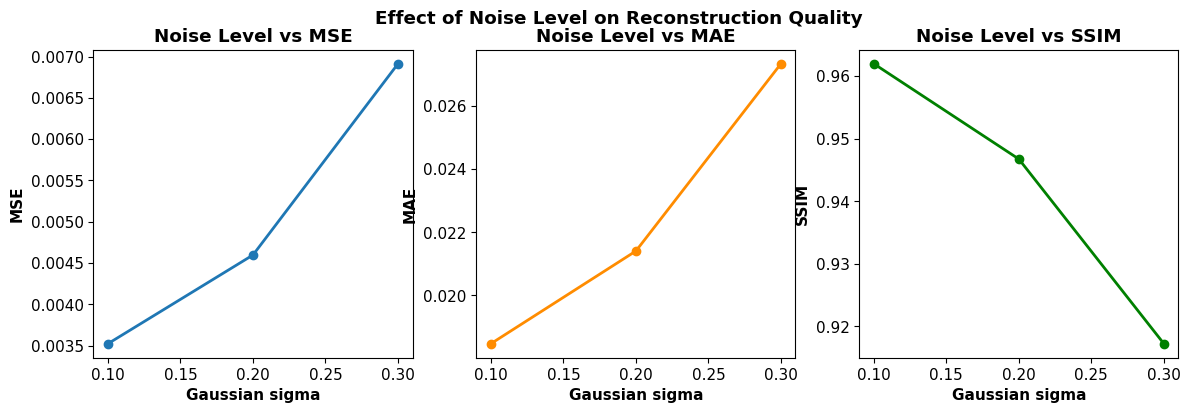

In [21]:
levels = gaussian_levels
mses = [denoise_metrics[s][0] for s in levels]
maes = [denoise_metrics[s][1] for s in levels]
ssims = [denoise_metrics[s][2] for s in levels]

print(f"{'Noise Level':<14}{'MSE':<12}{'MAE':<12}{'SSIM':<10}")
for s, m, a, ss in zip(levels, mses, maes, ssims):
    print(f"{s:<14}{m:<12.5f}{a:<12.5f}{ss:<10.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(levels, mses, marker="o", linewidth=2)
style_axes(axes[0], title="Noise Level vs MSE", xlabel="Gaussian sigma", ylabel="MSE")
axes[1].plot(levels, maes, marker="o", linewidth=2, color="darkorange")
style_axes(axes[1], title="Noise Level vs MAE", xlabel="Gaussian sigma", ylabel="MAE")
axes[2].plot(levels, ssims, marker="o", linewidth=2, color="green")
style_axes(axes[2], title="Noise Level vs SSIM", xlabel="Gaussian sigma", ylabel="SSIM")
fig.suptitle("Effect of Noise Level on Reconstruction Quality", fontweight="bold")
save_plot(fig, "plot5_noise_level_vs_quality.png")
plt.show()

### Plot 5b — Noise Level vs Reconstruction Quality (Salt-and-Pepper)

Noise Level (p)   MSE         MAE         SSIM      
0.05              0.00392     0.01901     0.9581    
0.1               0.00512     0.02214     0.9439    
0.2               0.00789     0.02855     0.9115    
Saved: plots/plot5b_saltpepper_noise_level_vs_quality.png


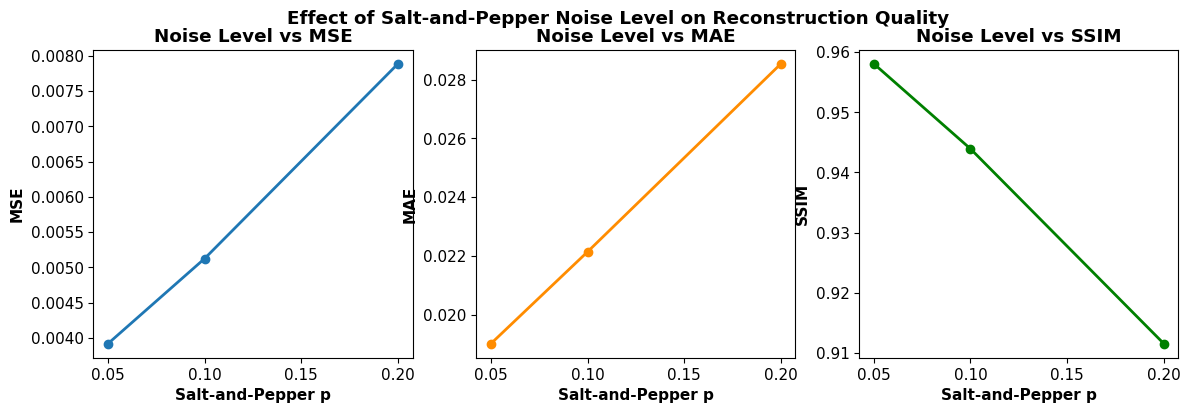

In [22]:
sp_levels_x = sp_levels
sp_mses = [sp_metrics[p][0] for p in sp_levels_x]
sp_maes = [sp_metrics[p][1] for p in sp_levels_x]
sp_ssims = [sp_metrics[p][2] for p in sp_levels_x]

print(f"{'Noise Level (p)':<18}{'MSE':<12}{'MAE':<12}{'SSIM':<10}")
for p, m, a, ss in zip(sp_levels_x, sp_mses, sp_maes, sp_ssims):
    print(f"{p:<18}{m:<12.5f}{a:<12.5f}{ss:<10.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(sp_levels_x, sp_mses, marker="o", linewidth=2)
style_axes(axes[0], title="Noise Level vs MSE", xlabel="Salt-and-Pepper p", ylabel="MSE")
axes[1].plot(sp_levels_x, sp_maes, marker="o", linewidth=2, color="darkorange")
style_axes(axes[1], title="Noise Level vs MAE", xlabel="Salt-and-Pepper p", ylabel="MAE")
axes[2].plot(sp_levels_x, sp_ssims, marker="o", linewidth=2, color="green")
style_axes(axes[2], title="Noise Level vs SSIM", xlabel="Salt-and-Pepper p", ylabel="SSIM")
fig.suptitle("Effect of Salt-and-Pepper Noise Level on Reconstruction Quality", fontweight="bold")
save_plot(fig, "plot5b_saltpepper_noise_level_vs_quality.png")
plt.show()

## 8. Variational Autoencoder (VAE)
Latent dimension = 2 (so the latent space can be visualized directly).

In [23]:
LATENT_DIM_VAE = 2

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

def build_vae_encoder(latent_dim=LATENT_DIM_VAE):
    inp = layers.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(inp)
    x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(16, activation="relu")(x)
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    return keras.Model(inp, [z_mean, z_log_var, z], name="VAE_Encoder")

def build_vae_decoder(latent_dim=LATENT_DIM_VAE):
    inp = layers.Input(shape=(latent_dim,))
    x = layers.Dense(7 * 7 * 64, activation="relu")(inp)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
    out = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)
    return keras.Model(inp, out, name="VAE_Decoder")

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.val_total_loss_tracker = keras.metrics.Mean(name="val_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def _compute_losses(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        return recon_loss, kl_loss, reconstruction

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            recon_loss, kl_loss, _ = self._compute_losses(data)
            total_loss = recon_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss": self.total_loss_tracker.result(),
                "reconstruction_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        recon_loss, kl_loss, _ = self._compute_losses(data)
        total_loss = recon_loss + kl_loss
        self.val_total_loss_tracker.update_state(total_loss)
        return {"loss": self.val_total_loss_tracker.result()}

    def call(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        return self.decoder(z)

In [24]:
reset_keras()
vae_encoder = build_vae_encoder()
vae_decoder = build_vae_decoder()
vae = VAE(vae_encoder, vae_decoder)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))
vae_encoder.summary()
vae_decoder.summary()

Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │     50,192 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         34 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 69,076 (269.83 KB)

 Trainable params: 69,076 (269.83 KB)

 Non-trainable params: 0 (0.00 B)

Model: "VAE_Decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
class ValLossHistory(keras.callbacks.Callback):
    # Records validation total-loss per epoch (test_step only reports 'loss')
    def __init__(self, val_data):
        super().__init__()
        self.val_data = val_data
        self.train_loss = []
        self.val_loss = []
    def on_epoch_end(self, epoch, logs=None):
        self.train_loss.append(logs.get("loss"))
        val_recon, val_kl, _ = self.model._compute_losses(self.val_data)
        self.val_loss.append(float(val_recon + val_kl))

val_hist_cb = ValLossHistory(x_test)

start = time.time()
vae_history = vae.fit(
    x_train, epochs=30, batch_size=128,
    validation_data=(x_test, x_test),
    callbacks=[val_hist_cb], verbose=2
)
vae_time = time.time() - start
print(f"VAE training time: {vae_time:.1f}s")

Epoch 1/30
79/79 - 12s - 155ms/step - kl_loss: 2.9607 - loss: 283.7960 - reconstruction_loss: 280.8353 - val_loss: 212.4992
Epoch 2/30
79/79 - 1s - 8ms/step - kl_loss: 3.3237 - loss: 206.4063 - reconstruction_loss: 203.0826 - val_loss: 206.5732
Epoch 3/30
79/79 - 1s - 8ms/step - kl_loss: 3.5160 - loss: 197.7663 - reconstruction_loss: 194.2503 - val_loss: 202.9181
Epoch 4/30
79/79 - 1s - 8ms/step - kl_loss: 3.8057 - loss: 191.9590 - reconstruction_loss: 188.1532 - val_loss: 199.0593
Epoch 5/30
79/79 - 1s - 8ms/step - kl_loss: 4.6868 - loss: 182.8028 - reconstruction_loss: 178.1160 - val_loss: 195.0698
Epoch 6/30
79/79 - 1s - 8ms/step - kl_loss: 4.6743 - loss: 177.5966 - reconstruction_loss: 172.9223 - val_loss: 191.9499
Epoch 7/30
79/79 - 1s - 8ms/step - kl_loss: 4.6393 - loss: 174.8925 - reconstruction_loss: 170.2532 - val_loss: 189.2775
Epoch 8/30
79/79 - 1s - 8ms/step - kl_loss: 4.7237 - loss: 171.9774 - reconstruction_loss: 167.2538 - val_loss: 186.9552
Epoch 9/30
79/79 - 1s - 8ms/s

In [26]:
vae_recon_loss, vae_kl_loss, vae_recon = vae._compute_losses(x_test)
vae_recon = vae_recon.numpy()
vae_total_loss = float(vae_recon_loss + vae_kl_loss)
vae_mse, vae_mae, vae_ssim = compute_metrics(x_test, vae_recon)

print(f"VAE  ->  Recon Loss: {float(vae_recon_loss):.3f}  KL Loss: {float(vae_kl_loss):.3f}  "
      f"Total Loss: {vae_total_loss:.3f}")
print(f"VAE  ->  MSE: {vae_mse:.5f}  MAE: {vae_mae:.5f}  SSIM: {vae_ssim:.4f}  "
      f"Params: {count_params(vae_encoder) + count_params(vae_decoder)}")

VAE  ->  Recon Loss: 152.362  KL Loss: 5.692  Total Loss: 158.054
VAE  ->  MSE: 0.04492  MAE: 0.10270  SSIM: 0.5058  Params: 134165


### Plot 9 (report numbering) — VAE Training vs Validation Loss

Saved: plots/plot9_vae_loss_curve.png


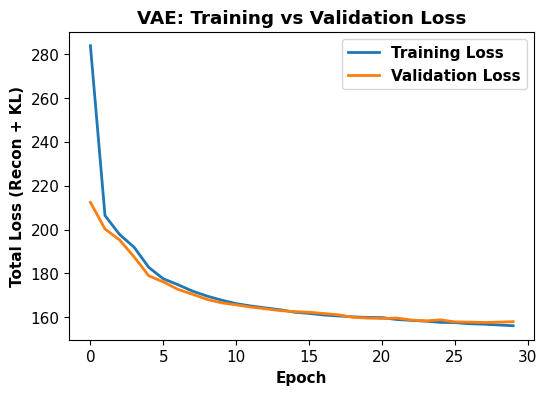

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(val_hist_cb.train_loss, label="Training Loss", linewidth=2)
ax.plot(val_hist_cb.val_loss, label="Validation Loss", linewidth=2)
style_axes(ax, title="VAE: Training vs Validation Loss", xlabel="Epoch", ylabel="Total Loss (Recon + KL)", legend=True)
save_plot(fig, "plot9_vae_loss_curve.png")
plt.show()

### Plot 6 — VAE Latent-Space Visualization (2-D)

Saved: plots/plot6_vae_latent_space.png


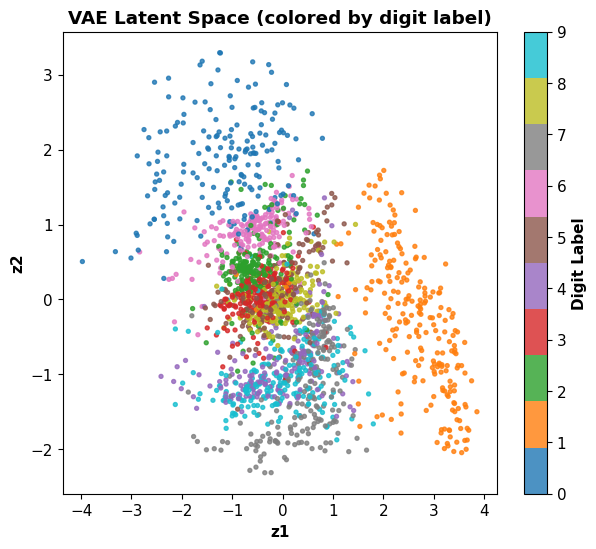

In [28]:
z_mean_test, _, _ = vae_encoder.predict(x_test, verbose=0)

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(z_mean_test[:, 0], z_mean_test[:, 1], c=y_test, cmap="tab10", s=8, alpha=0.8)
cbar = fig.colorbar(scatter, ax=ax, ticks=range(10))
cbar.set_label("Digit Label", fontweight="bold")
style_axes(ax, title="VAE Latent Space (colored by digit label)", xlabel="z1", ylabel="z2")
save_plot(fig, "plot6_vae_latent_space.png")
plt.show()

### Plot 7 — Randomly Generated VAE Images

Saved: plots/plot7_vae_generated_samples.png


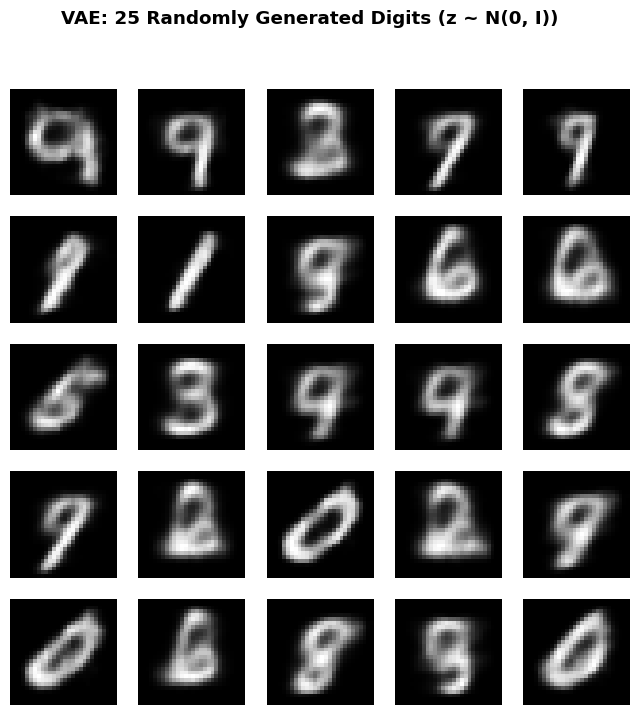

In [29]:
n_gen = 25
z_random = np.random.normal(0, 1, size=(n_gen, LATENT_DIM_VAE))
generated = vae_decoder.predict(z_random, verbose=0)

grid = int(np.ceil(np.sqrt(n_gen)))
fig, axes = plt.subplots(grid, grid, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    if i < n_gen:
        ax.imshow(generated[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
fig.suptitle("VAE: 25 Randomly Generated Digits (z ~ N(0, I))", fontweight="bold")
save_plot(fig, "plot7_vae_generated_samples.png")
plt.show()

### Plot 8 — Latent-Space Interpolation

Saved: plots/plot8_vae_latent_interpolation.png


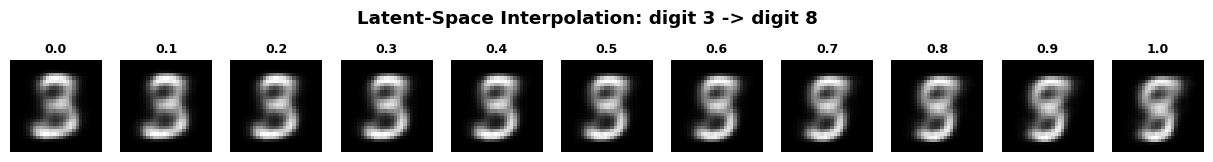

In [30]:
# Pick two test images of different digits and interpolate between their latent means
idx_a = int(np.where(y_test == 3)[0][0])
idx_b = int(np.where(y_test == 8)[0][0])
z_a = z_mean_test[idx_a]
z_b = z_mean_test[idx_b]

alphas = np.linspace(0, 1, 11)
z_interp = np.array([(1 - a) * z_a + a * z_b for a in alphas])
decoded_interp = vae_decoder.predict(z_interp, verbose=0)

fig, axes = plt.subplots(1, len(alphas), figsize=(1.4 * len(alphas), 2))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"{alphas[i]:.1f}", fontweight="bold", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Latent-Space Interpolation: digit {y_test[idx_a]} -> digit {y_test[idx_b]}", fontweight="bold")
save_plot(fig, "plot8_vae_latent_interpolation.png")
plt.show()

## 9. Reconstruction-Error Distribution and High-Error Samples (on the Convolutional AE)

Saved: plots/plot10_reconstruction_error_distribution.png


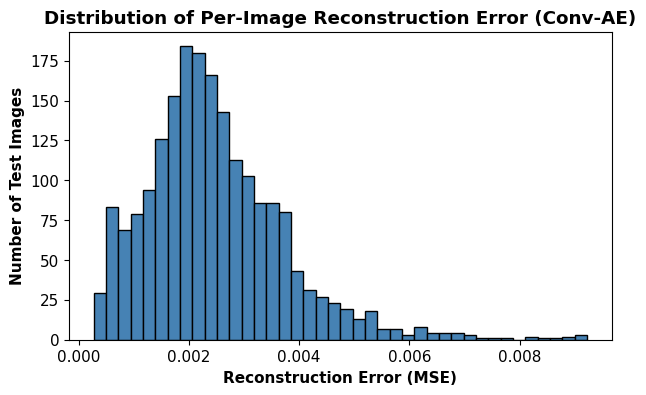

Error range: [0.00027, 0.00922]   Mean: 0.00248   Std: 0.00127


In [31]:
errors = per_image_error(x_test, cae_recon)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(errors, bins=40, color="steelblue", edgecolor="black")
style_axes(ax, title="Distribution of Per-Image Reconstruction Error (Conv-AE)",
           xlabel="Reconstruction Error (MSE)", ylabel="Number of Test Images")
save_plot(fig, "plot10_reconstruction_error_distribution.png")
plt.show()

print(f"Error range: [{errors.min():.5f}, {errors.max():.5f}]   Mean: {errors.mean():.5f}   Std: {errors.std():.5f}")

Saved: plots/plot_highest_error_samples.png


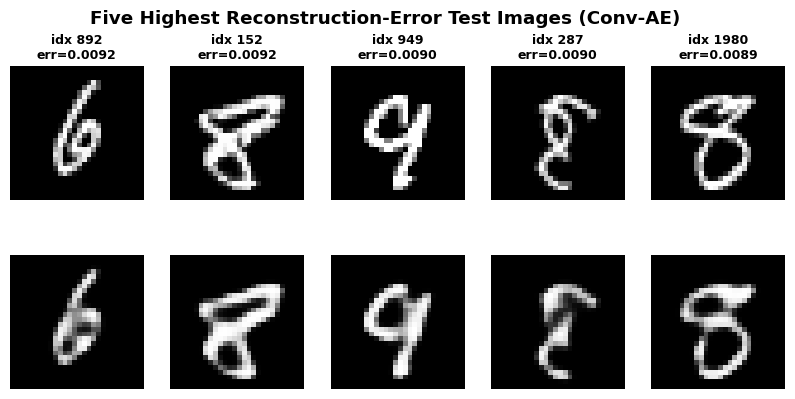

In [32]:
top5_idx = np.argsort(errors)[-5:][::-1]

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for col, idx in enumerate(top5_idx):
    axes[0, col].imshow(x_test[idx].reshape(28, 28), cmap="gray")
    axes[0, col].set_title(f"idx {idx}\nerr={errors[idx]:.4f}", fontsize=9, fontweight="bold")
    axes[0, col].axis("off")
    axes[1, col].imshow(cae_recon[idx].reshape(28, 28), cmap="gray")
    axes[1, col].axis("off")
axes[0, 0].set_ylabel("Original", fontweight="bold")
axes[1, 0].set_ylabel("Reconstruction", fontweight="bold")
fig.suptitle("Five Highest Reconstruction-Error Test Images (Conv-AE)", fontweight="bold")
save_plot(fig, "plot_highest_error_samples.png")
plt.show()

## 10. Consolidated Results

In [33]:
consolidated = {
    "FC Autoencoder":     {"MSE": fc_mse,      "MAE": fc_mae,      "SSIM": fc_ssim,      "Params": count_params(fc_ae),  "Time (s)": fc_time},
    "Conv. Autoencoder":  {"MSE": cae_mse,      "MAE": cae_mae,      "SSIM": cae_ssim,      "Params": count_params(cae),    "Time (s)": cae_time},
    "Denoising CAE":      {"MSE": denoise_mse,  "MAE": denoise_mae,  "SSIM": denoise_ssim,  "Params": count_params(denoise_cae), "Time (s)": denoise_time},
    "VAE": {"MSE": vae_mse, "MAE": vae_mae, "SSIM": vae_ssim,
            "Params": count_params(vae_encoder) + count_params(vae_decoder), "Time (s)": vae_time},
}

print(f"{'Model':<20}{'MSE':<12}{'MAE':<12}{'SSIM':<10}{'Params':<10}{'Time (s)'}")
for name, m in consolidated.items():
    print(f"{name:<20}{m['MSE']:<12.5f}{m['MAE']:<12.5f}{m['SSIM']:<10.4f}{m['Params']:<10}{m['Time (s)']:.1f}")

print("\nVAE loss breakdown:")
print(f"  Reconstruction Loss: {float(vae_recon_loss):.3f}")
print(f"  KL Loss:             {float(vae_kl_loss):.3f}")
print(f"  Total Loss:          {vae_total_loss:.3f}")

Model               MSE         MAE         SSIM      Params    Time (s)
FC Autoencoder      0.01996     0.05433     0.7733    211040    13.5
Conv. Autoencoder   0.00248     0.01506     0.9748    74497     24.2
Denoising CAE       0.00460     0.02141     0.9467    74497     16.2
VAE                 0.04492     0.10270     0.5058    134165    31.5

VAE loss breakdown:
  Reconstruction Loss: 152.362
  KL Loss:             5.692
  Total Loss:          158.054


## 11. Additional Latent-Dimension Study (FC Autoencoder)
Repeats the fully connected autoencoder for `latent_dim` in {2, 8, 16, 32}.

In [34]:
latent_dims = [2, 8, 16, 32]
latent_study = {}

for dz in latent_dims:
    print(f"\n=== Training FC-AE with latent_dim={dz} ===")
    reset_keras()
    model, _ = build_fc_autoencoder(latent_dim=dz)
    model.fit(x_train_flat, x_train_flat,
              validation_data=(x_test_flat, x_test_flat),
              epochs=15, batch_size=128, verbose=0)
    recon = model.predict(x_test_flat, verbose=0)
    mse, mae, ssim_v = compute_metrics(x_test_flat, recon)
    latent_study[dz] = {"MSE": mse, "SSIM": ssim_v, "Params": count_params(model)}
    print(f"latent_dim={dz}  MSE={mse:.5f}  SSIM={ssim_v:.4f}  Params={count_params(model)}")


=== Training FC-AE with latent_dim=2 ===


latent_dim=2  MSE=0.05012  SSIM=0.4338  Params=210130

=== Training FC-AE with latent_dim=8 ===
latent_dim=8  MSE=0.02792  SSIM=0.6936  Params=210520

=== Training FC-AE with latent_dim=16 ===
latent_dim=16  MSE=0.02287  SSIM=0.7384  Params=211040

=== Training FC-AE with latent_dim=32 ===
latent_dim=32  MSE=0.02074  SSIM=0.7615  Params=212080


### Plot 10 — Latent Dimension vs Reconstruction MSE

Saved: plots/plot_latent_dim_vs_mse.png


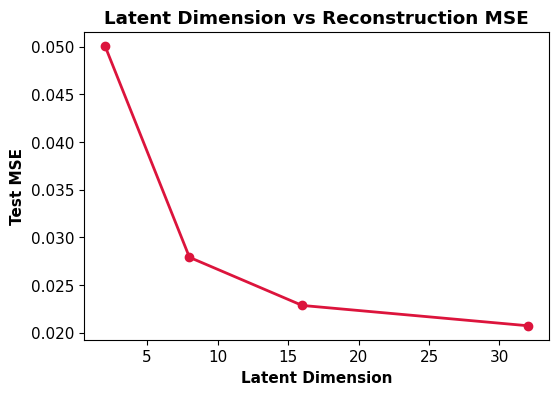

Latent Dim    MSE         SSIM      Params    
2             0.05012     0.4338    210130    
8             0.02792     0.6936    210520    
16            0.02287     0.7384    211040    
32            0.02074     0.7615    212080    


In [35]:
dims = latent_dims
mses_dim = [latent_study[d]["MSE"] for d in dims]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(dims, mses_dim, marker="o", linewidth=2, color="crimson")
style_axes(ax, title="Latent Dimension vs Reconstruction MSE", xlabel="Latent Dimension", ylabel="Test MSE")
save_plot(fig, "plot_latent_dim_vs_mse.png")
plt.show()

print(f"{'Latent Dim':<14}{'MSE':<12}{'SSIM':<10}{'Params':<10}")
for d in dims:
    s = latent_study[d]
    print(f"{d:<14}{s['MSE']:<12.5f}{s['SSIM']:<10.4f}{s['Params']:<10}")

## 13. Additional Exercises

### Exercise 1 — Convolutional AE with latent dimensions 4, 8, 16, 32

In [36]:
def build_conv_autoencoder_bottleneck(latent_dim):
    # Same conv/pool feature extractor as the main CAE, but funneled through an explicit
    # Dense bottleneck of size `latent_dim` so the latent size can be swept numerically.
    inp = layers.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)          # -> (7, 7, 64)
    x = layers.Flatten()(x)
    z = layers.Dense(latent_dim, activation="relu", name="latent")(x)

    x = layers.Dense(7 * 7 * 64, activation="relu")(z)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

    model = keras.Model(inp, out, name=f"CAE_bottleneck_z{latent_dim}")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

cae_latent_dims = [4, 8, 16, 32]
cae_latent_study = {}

for dz in cae_latent_dims:
    print(f"\\n=== Training bottleneck CAE with latent_dim={dz} ===")
    reset_keras()
    model = build_conv_autoencoder_bottleneck(dz)
    model.fit(x_train, x_train, validation_data=(x_test, x_test),
              epochs=15, batch_size=128, verbose=0)
    recon = model.predict(x_test, verbose=0)
    mse, mae, ssim_v = compute_metrics(x_test, recon)
    cae_latent_study[dz] = {"MSE": mse, "MAE": mae, "SSIM": ssim_v, "Params": count_params(model), "recon": recon}
    print(f"latent_dim={dz}  MSE={mse:.5f}  MAE={mae:.5f}  SSIM={ssim_v:.4f}  Params={count_params(model)}")

\n=== Training bottleneck CAE with latent_dim=4 ===
latent_dim=4  MSE=0.04214  MAE=0.09814  SSIM=0.5471  Params=65797
\n=== Training bottleneck CAE with latent_dim=8 ===
latent_dim=8  MSE=0.02854  MAE=0.07092  SSIM=0.6978  Params=90889
\n=== Training bottleneck CAE with latent_dim=16 ===
latent_dim=16  MSE=0.02194  MAE=0.05784  SSIM=0.7668  Params=141073
\n=== Training bottleneck CAE with latent_dim=32 ===
latent_dim=32  MSE=0.01267  MAE=0.03883  SSIM=0.8654  Params=241441


Saved: plots/ex1_cae_latent_dim_sweep.png


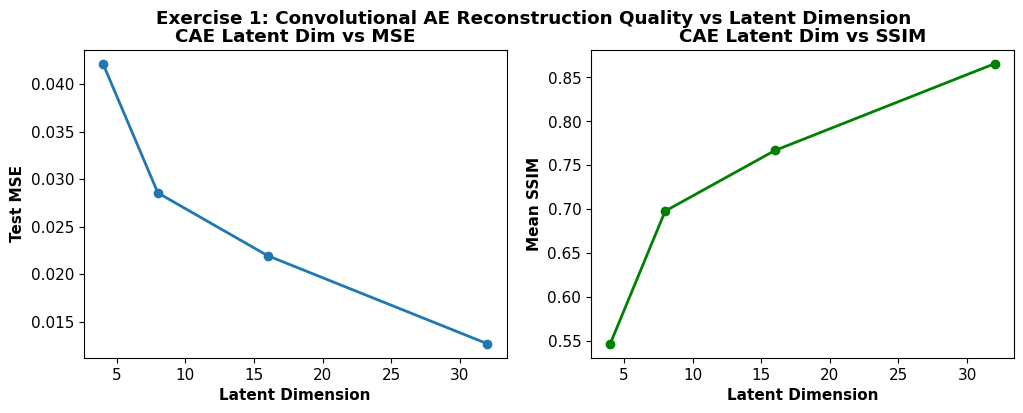

Latent Dim    MSE         MAE         SSIM      Params    
4             0.04214     0.09814     0.5471    65797     
8             0.02854     0.07092     0.6978    90889     
16            0.02194     0.05784     0.7668    141073    
32            0.01267     0.03883     0.8654    241441    


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cae_latent_dims, [cae_latent_study[d]["MSE"] for d in cae_latent_dims], marker="o", linewidth=2)
style_axes(ax[0], title="CAE Latent Dim vs MSE", xlabel="Latent Dimension", ylabel="Test MSE")
ax[1].plot(cae_latent_dims, [cae_latent_study[d]["SSIM"] for d in cae_latent_dims], marker="o", linewidth=2, color="green")
style_axes(ax[1], title="CAE Latent Dim vs SSIM", xlabel="Latent Dimension", ylabel="Mean SSIM")
fig.suptitle("Exercise 1: Convolutional AE Reconstruction Quality vs Latent Dimension", fontweight="bold")
save_plot(fig, "ex1_cae_latent_dim_sweep.png")
plt.show()

print(f"{'Latent Dim':<14}{'MSE':<12}{'MAE':<12}{'SSIM':<10}{'Params':<10}")
for d in cae_latent_dims:
    s = cae_latent_study[d]
    print(f"{d:<14}{s['MSE']:<12.5f}{s['MAE']:<12.5f}{s['SSIM']:<10.4f}{s['Params']:<10}")

### Exercise 2 — Gaussian vs Salt-and-Pepper Denoising (same architecture)

In [38]:
# Reuse the sigma=0.2 Gaussian model (Section 7) and the p=0.10 salt-and-pepper model
# (Section 7) — both share the same denoising-CAE architecture, so this is a direct,
# like-for-like comparison of the two corruption types without retraining.
gauss_mse, gauss_mae, gauss_ssim = denoise_metrics[0.2]
sp_mse2, sp_mae2, sp_ssim2 = sp_metrics[0.10]

x_test_g = add_gaussian_noise(x_test, 0.2)
gauss_recon = denoise_cae.predict(x_test_g, verbose=0)
x_test_sp = add_salt_and_pepper_noise(x_test, 0.10)
sp_recon = sp_denoise_model.predict(x_test_sp, verbose=0)

print(f"{'Noise Type':<20}{'MSE':<12}{'MAE':<12}{'SSIM':<10}")
print(f"{'Gaussian (0.2)':<20}{gauss_mse:<12.5f}{gauss_mae:<12.5f}{gauss_ssim:<10.4f}")
print(f"{'Salt-and-Pepper(0.1)':<20}{sp_mse2:<12.5f}{sp_mae2:<12.5f}{sp_ssim2:<10.4f}")

Noise Type          MSE         MAE         SSIM      
Gaussian (0.2)      0.00460     0.02141     0.9467    
Salt-and-Pepper(0.1)0.00512     0.02214     0.9439    


Saved: plots/ex2_gaussian_vs_saltpepper.png


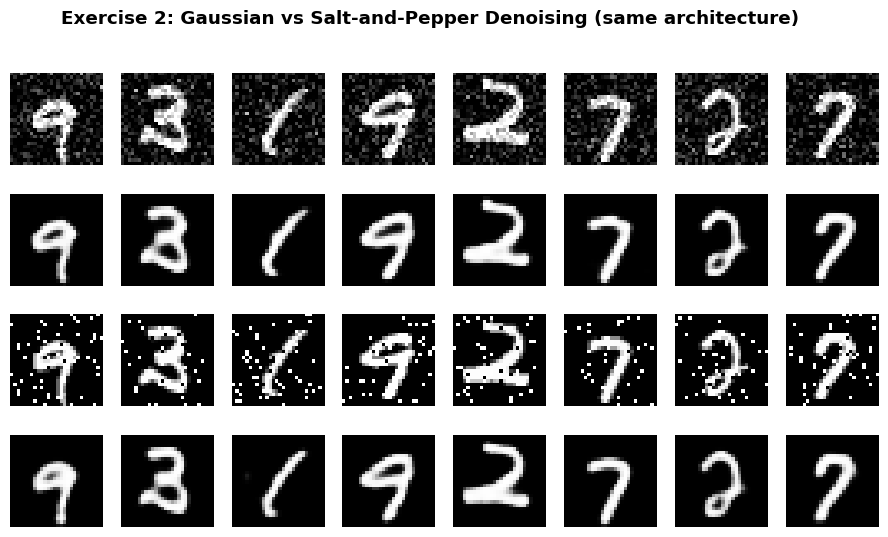

In [39]:
n = 8
fig, axes = plt.subplots(4, n, figsize=(1.4 * n, 6.0))
for i in range(n):
    axes[0, i].imshow(x_test_g[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(gauss_recon[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(x_test_sp[i].reshape(28, 28), cmap="gray"); axes[2, i].axis("off")
    axes[3, i].imshow(sp_recon[i].reshape(28, 28), cmap="gray"); axes[3, i].axis("off")
axes[0, 0].set_ylabel("Gaussian Noisy", fontweight="bold")
axes[1, 0].set_ylabel("Gaussian Denoised", fontweight="bold")
axes[2, 0].set_ylabel("S&P Noisy", fontweight="bold")
axes[3, 0].set_ylabel("S&P Denoised", fontweight="bold")
fig.suptitle("Exercise 2: Gaussian vs Salt-and-Pepper Denoising (same architecture)", fontweight="bold")
save_plot(fig, "ex2_gaussian_vs_saltpepper.png")
plt.show()

### Exercise 3 — Two Denoising Models Compared by SSIM (sigma = 0.1 vs 0.3)

In [40]:
low, high = 0.1, 0.3
print(f"sigma={low}  ->  SSIM={denoise_metrics[low][2]:.4f}")
print(f"sigma={high}  ->  SSIM={denoise_metrics[high][2]:.4f}")
print(f"SSIM drop from sigma={low} to sigma={high}: {denoise_metrics[low][2] - denoise_metrics[high][2]:.4f}")

sigma=0.1  ->  SSIM=0.9620
sigma=0.3  ->  SSIM=0.9172
SSIM drop from sigma=0.1 to sigma=0.3: 0.0447


### Exercise 4 — Transposed-Convolution Decoder vs UpSampling2D Decoder

In [41]:
def build_conv_autoencoder_transpose():
    inp = layers.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)
    z = layers.Conv2D(64, 3, activation="relu", padding="same", name="latent_feature_map")(x)

    x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(z)
    out = layers.Conv2DTranspose(1, 3, activation="sigmoid", strides=2, padding="same")(x)

    model = keras.Model(inp, out, name="Conv_AE_Transpose")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

reset_keras()
cae_transpose = build_conv_autoencoder_transpose()
cae_transpose.fit(x_train, x_train, validation_data=(x_test, x_test), epochs=15, batch_size=128, verbose=0)
transpose_recon = cae_transpose.predict(x_test, verbose=0)
tr_mse, tr_mae, tr_ssim = compute_metrics(x_test, transpose_recon)

print(f"{'Decoder Type':<22}{'MSE':<12}{'MAE':<12}{'SSIM':<10}{'Params':<10}")
print(f"{'UpSampling2D (orig.)':<22}{cae_mse:<12.5f}{cae_mae:<12.5f}{cae_ssim:<10.4f}{count_params(cae):<10}")
print(f"{'Conv2DTranspose':<22}{tr_mse:<12.5f}{tr_mae:<12.5f}{tr_ssim:<10.4f}{count_params(cae_transpose):<10}")

Decoder Type          MSE         MAE         SSIM      Params    
UpSampling2D (orig.)  0.00248     0.01506     0.9748    74497     
Conv2DTranspose       0.00263     0.01529     0.9740    74497     


Saved: plots/ex4_upsampling_vs_transpose.png


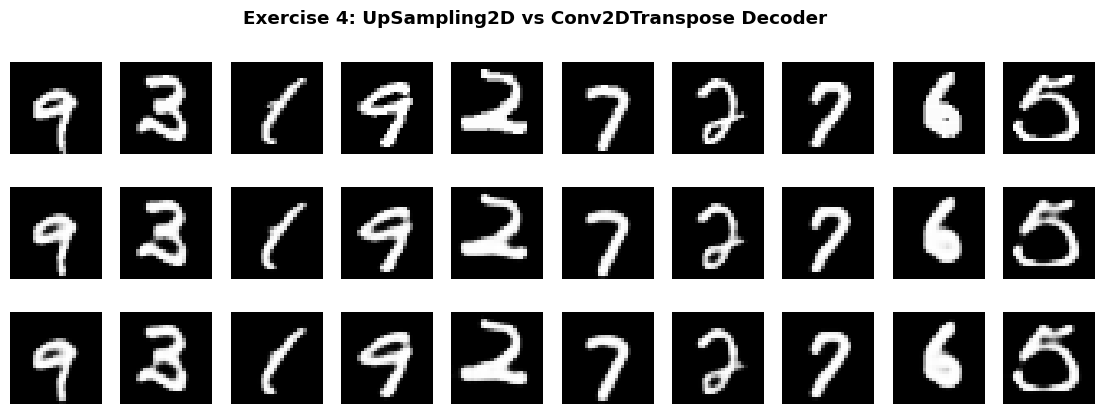

In [42]:
n = 10
fig, axes = plt.subplots(3, n, figsize=(1.4 * n, 4.6))
for i in range(n):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(cae_recon[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
    axes[2, i].imshow(transpose_recon[i].reshape(28, 28), cmap="gray"); axes[2, i].axis("off")
axes[0, 0].set_ylabel("Original", fontweight="bold")
axes[1, 0].set_ylabel("UpSampling2D", fontweight="bold")
axes[2, 0].set_ylabel("Conv2DTranspose", fontweight="bold")
fig.suptitle("Exercise 4: UpSampling2D vs Conv2DTranspose Decoder", fontweight="bold")
save_plot(fig, "ex4_upsampling_vs_transpose.png")
plt.show()

### Exercise 5 — VAE with Latent Dimension 2 vs 8

In [43]:
reset_keras()
vae_encoder_8 = build_vae_encoder(latent_dim=8)
vae_decoder_8 = build_vae_decoder(latent_dim=8)
vae_8 = VAE(vae_encoder_8, vae_decoder_8)
vae_8.compile(optimizer=keras.optimizers.Adam(1e-3))
vae_8.fit(x_train, epochs=20, batch_size=128, validation_data=(x_test, x_test), verbose=0)

recon_loss_8, kl_loss_8, recon_8 = vae_8._compute_losses(x_test)
recon_8 = recon_8.numpy()
mse_8, mae_8, ssim_8 = compute_metrics(x_test, recon_8)

print(f"{'VAE':<12}{'Recon Loss':<14}{'KL Loss':<12}{'MSE':<12}{'SSIM':<10}")
print(f"{'z_dim=2':<12}{float(vae_recon_loss):<14.3f}{float(vae_kl_loss):<12.3f}{vae_mse:<12.5f}{vae_ssim:<10.4f}")
print(f"{'z_dim=8':<12}{float(recon_loss_8):<14.3f}{float(kl_loss_8):<12.3f}{mse_8:<12.5f}{ssim_8:<10.4f}")

VAE         Recon Loss    KL Loss     MSE         SSIM      
z_dim=2     152.362       5.692       0.04492     0.5058    
z_dim=8     119.552       12.660      0.03040     0.6830    


Saved: plots/ex5_vae_latent8_recon.png


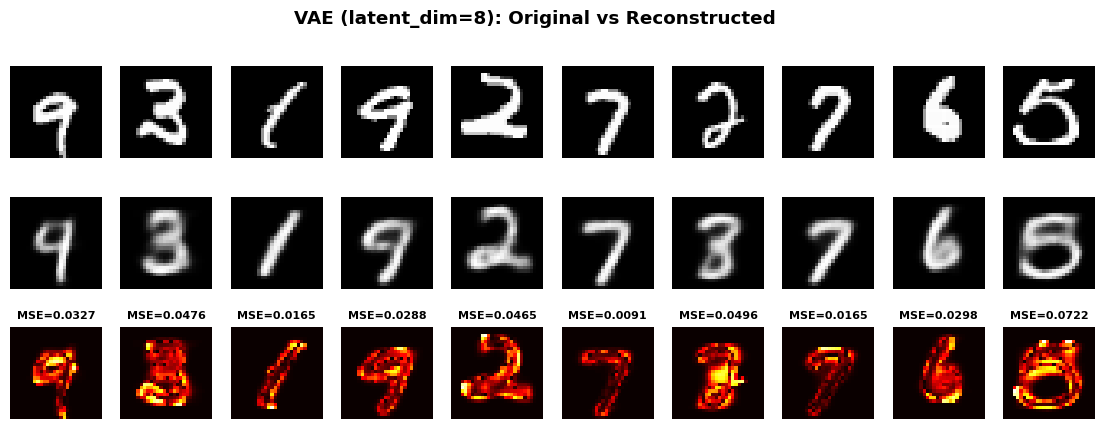

In [44]:
plot_original_vs_recon(x_test, recon_8, n=10,
                        title="VAE (latent_dim=8): Original vs Reconstructed",
                        fname="ex5_vae_latent8_recon.png")

### Exercise 6 — Effect of Increasing the KL-Loss Weight (beta-VAE)

In [45]:
class BetaVAE(VAE):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(encoder, decoder, **kwargs)
        self.beta = beta

    def _compute_losses(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(keras.losses.binary_crossentropy(data, reconstruction), axis=(1, 2))
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        return recon_loss, self.beta * kl_loss, reconstruction

betas = [1.0, 5.0]
beta_results = {}

for beta in betas:
    print(f"\\n=== Training beta-VAE with beta={beta} ===")
    reset_keras()
    enc = build_vae_encoder(latent_dim=2)
    dec = build_vae_decoder(latent_dim=2)
    bvae = BetaVAE(enc, dec, beta=beta)
    bvae.compile(optimizer=keras.optimizers.Adam(1e-3))
    bvae.fit(x_train, epochs=20, batch_size=128, validation_data=(x_test, x_test), verbose=0)
    r_loss, k_loss, recon = bvae._compute_losses(x_test)
    recon = recon.numpy()
    mse_b, mae_b, ssim_b = compute_metrics(x_test, recon)
    z_mean_b, _, _ = enc.predict(x_test, verbose=0)
    beta_results[beta] = {"recon_loss": float(r_loss), "kl_loss": float(k_loss),
                           "MSE": mse_b, "SSIM": ssim_b, "z_mean": z_mean_b}
    print(f"beta={beta}  ReconLoss={float(r_loss):.3f}  KLLoss={float(k_loss):.3f}  "
          f"MSE={mse_b:.5f}  SSIM={ssim_b:.4f}")

\n=== Training beta-VAE with beta=1.0 ===
beta=1.0  ReconLoss=160.572  KLLoss=5.730  MSE=0.04877  SSIM=0.4578
\n=== Training beta-VAE with beta=5.0 ===
beta=5.0  ReconLoss=182.508  KLLoss=8.093  MSE=0.05792  SSIM=0.3257


Saved: plots/ex6_beta_vae_latent_space.png


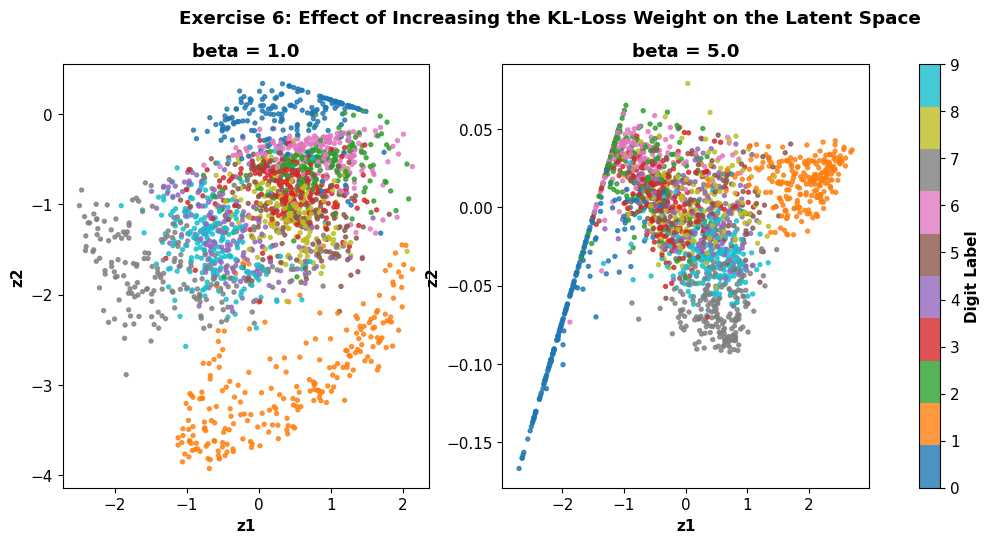

beta    Recon Loss    KL Loss     MSE         SSIM      
1.0     160.572       5.730       0.04877     0.4578    
5.0     182.508       8.093       0.05792     0.3257    


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, beta in zip(axes, betas):
    zb = beta_results[beta]["z_mean"]
    sc = ax.scatter(zb[:, 0], zb[:, 1], c=y_test, cmap="tab10", s=8, alpha=0.8)
    style_axes(ax, title=f"beta = {beta}", xlabel="z1", ylabel="z2")
cbar = fig.colorbar(sc, ax=axes, ticks=range(10))
cbar.set_label("Digit Label", fontweight="bold")
fig.suptitle("Exercise 6: Effect of Increasing the KL-Loss Weight on the Latent Space", fontweight="bold")
save_plot(fig, "ex6_beta_vae_latent_space.png")
plt.show()

print(f"{'beta':<8}{'Recon Loss':<14}{'KL Loss':<12}{'MSE':<12}{'SSIM':<10}")
for beta in betas:
    r = beta_results[beta]
    print(f"{beta:<8}{r['recon_loss']:<14.3f}{r['kl_loss']:<12.3f}{r['MSE']:<12.5f}{r['SSIM']:<10.4f}")

### Exercise 7 — Larger Grid of VAE Samples (n = 100) and Diversity

Saved: plots/ex7_vae_generated_100.png


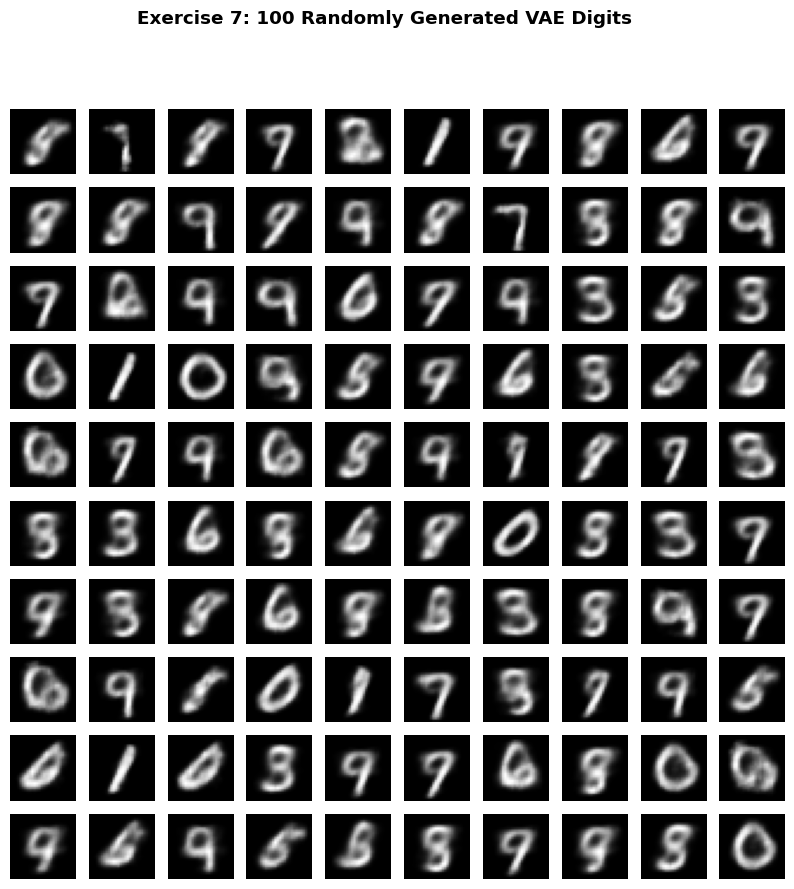

Mean pairwise pixel MAE among 30 generated samples (higher = more diverse): 0.1003


In [47]:
n_gen_large = 100
z_random_large = np.random.normal(0, 1, size=(n_gen_large, LATENT_DIM_VAE))
generated_large = vae_decoder.predict(z_random_large, verbose=0)

grid = int(np.ceil(np.sqrt(n_gen_large)))
fig, axes = plt.subplots(grid, grid, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < n_gen_large:
        ax.imshow(generated_large[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
fig.suptitle(f"Exercise 7: {n_gen_large} Randomly Generated VAE Digits", fontweight="bold")
save_plot(fig, "ex7_vae_generated_100.png")
plt.show()

# crude diversity proxy: mean pairwise pixel-wise MAE across a random subsample of generated images
sample_idx = np.random.choice(n_gen_large, size=30, replace=False)
sample_imgs = generated_large[sample_idx].reshape(30, -1)
pairwise_mae = np.mean([
    np.mean(np.abs(sample_imgs[i] - sample_imgs[j]))
    for i in range(30) for j in range(i + 1, 30)
])
print(f"Mean pairwise pixel MAE among 30 generated samples (higher = more diverse): {pairwise_mae:.4f}")

### Exercise 8 — Second Latent-Space Interpolation (a different digit pair)

Saved: plots/ex8_latent_interpolation_pair2.png


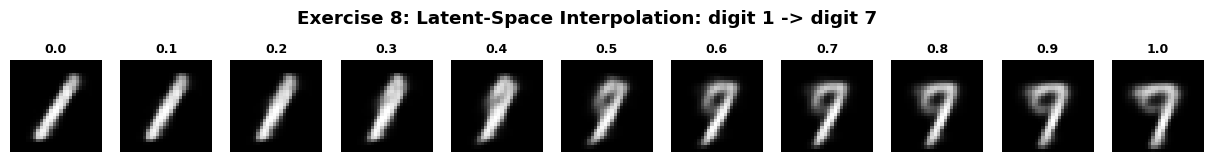

In [48]:
idx_c = int(np.where(y_test == 1)[0][0])
idx_d = int(np.where(y_test == 7)[0][0])
z_c = z_mean_test[idx_c]
z_d = z_mean_test[idx_d]

alphas2 = np.linspace(0, 1, 11)
z_interp2 = np.array([(1 - a) * z_c + a * z_d for a in alphas2])
decoded_interp2 = vae_decoder.predict(z_interp2, verbose=0)

fig, axes = plt.subplots(1, len(alphas2), figsize=(1.4 * len(alphas2), 2))
for i, ax in enumerate(axes):
    ax.imshow(decoded_interp2[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"{alphas2[i]:.1f}", fontweight="bold", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Exercise 8: Latent-Space Interpolation: digit {y_test[idx_c]} -> digit {y_test[idx_d]}", fontweight="bold")
save_plot(fig, "ex8_latent_interpolation_pair2.png")
plt.show()